# Bài Thực Hành 3: Dự Đoán Chuỗi Thời Gian Sử Dụng Machine Learning Models

**Mục tiêu:**
- Chuyển bài toán chuỗi thời gian sang học có giám sát (Supervised Learning).
- Huấn luyện mô hình XGBoost Regressor.
- Đánh giá chất lượng dự báo.

## Bước 1. Chuẩn bị dữ liệu

- Đọc dữ liệu `AEP_hourly.csv` (tiêu thụ điện hàng giờ từ PJM, đơn vị Megawatt).
- Định dạng cột `Datetime`, sắp xếp theo trình tự thời gian.
- Xử lý các mốc trùng lặp (Daylight Saving Time) và nội suy các mốc thời gian thiếu.
- Thống kê mô tả (`describe`) chuỗi dữ liệu.
- Vẽ biểu đồ trực quan hóa chuỗi thời gian cùng các đường ngưỡng thống kê (`mean`, `min`, `max`), chú thích đặc trưng và lưu ảnh vào thư mục `docs/images/`.

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Tạo thư mục lưu ảnh nếu chưa có
os.makedirs('../docs/images', exist_ok=True)

In [6]:
# 1. Đọc dữ liệu thô
data_path = '../data/raw/AEP_hourly.csv' if os.path.exists('../data/raw/AEP_hourly.csv') else '../data/AEP_hourly.csv'
df_raw = pd.read_csv(data_path)

# 2. Chuyển đổi Datetime và sắp xếp tăng dần
df_raw['Datetime'] = pd.to_datetime(df_raw['Datetime'])
df_sorted = df_raw.sort_values('Datetime').reset_index(drop=True)

# 3. Xử lý trùng lặp giờ (DST) và tạo lưới thời gian đều 1 giờ (freq='h')
series = df_sorted.groupby('Datetime')['AEP_MW'].mean().asfreq('h')
series = series.interpolate(method='time')

print('Dữ liệu sau khi làm sạch và tạo chuỗi liên tục:')
print(series.head())
print(f'\nTổng số giờ liên tục: {len(series):,} quan sát (từ {series.index.min()} đến {series.index.max()})')
print(f'Số giá trị khuyết (NaN): {series.isnull().sum()}')

Dữ liệu sau khi làm sạch và tạo chuỗi liên tục:
Datetime
2004-10-01 01:00:00    12379.0
2004-10-01 02:00:00    11935.0
2004-10-01 03:00:00    11692.0
2004-10-01 04:00:00    11597.0
2004-10-01 05:00:00    11681.0
Freq: h, Name: AEP_MW, dtype: float64

Tổng số giờ liên tục: 121,296 quan sát (từ 2004-10-01 01:00:00 đến 2018-08-03 00:00:00)
Số giá trị khuyết (NaN): 0


In [7]:
# 4. Thống kê mô tả dữ liệu (describe)
stats = series.describe()
print('Thống kê mô tả (describe) của chuỗi phụ tải AEP_MW:')
print(stats)

min_date = series.idxmin()
max_date = series.idxmax()
print('\nCác chỉ số thống kê chính:')
print(f'- Số quan sát (count):   {stats["count"]:,.0f} giờ')
print(f'- Trung bình (mean):     {stats["mean"]:,.2f} MW')
print(f'- Độ lệch chuẩn (std):  {stats["std"]:,.2f} MW')
print(f'- Thấp nhất (min):       {stats["min"]:,.2f} MW (vào lúc {min_date})')
print(f'- Tứ phân vị 25% (Q1):   {stats["25%"]:,.2f} MW')
print(f'- Trung vị (50% / Q2):   {stats["50%"]:,.2f} MW')
print(f'- Tứ phân vị 75% (Q3):   {stats["75%"]:,.2f} MW')
print(f'- Cao nhất (max):        {stats["max"]:,.2f} MW (vào lúc {max_date})')

Thống kê mô tả (describe) của chuỗi phụ tải AEP_MW:
count    121296.000000
mean      15499.150331
std        2591.379068
min        9581.000000
25%       13629.000000
50%       15309.000000
75%       17200.000000
max       25695.000000
Name: AEP_MW, dtype: float64

Các chỉ số thống kê chính:
- Số quan sát (count):   121,296 giờ
- Trung bình (mean):     15,499.15 MW
- Độ lệch chuẩn (std):  2,591.38 MW
- Thấp nhất (min):       9,581.00 MW (vào lúc 2016-10-02 05:00:00)
- Tứ phân vị 25% (Q1):   13,629.00 MW
- Trung vị (50% / Q2):   15,309.00 MW
- Tứ phân vị 75% (Q3):   17,200.00 MW
- Cao nhất (max):        25,695.00 MW (vào lúc 2008-10-20 14:00:00)


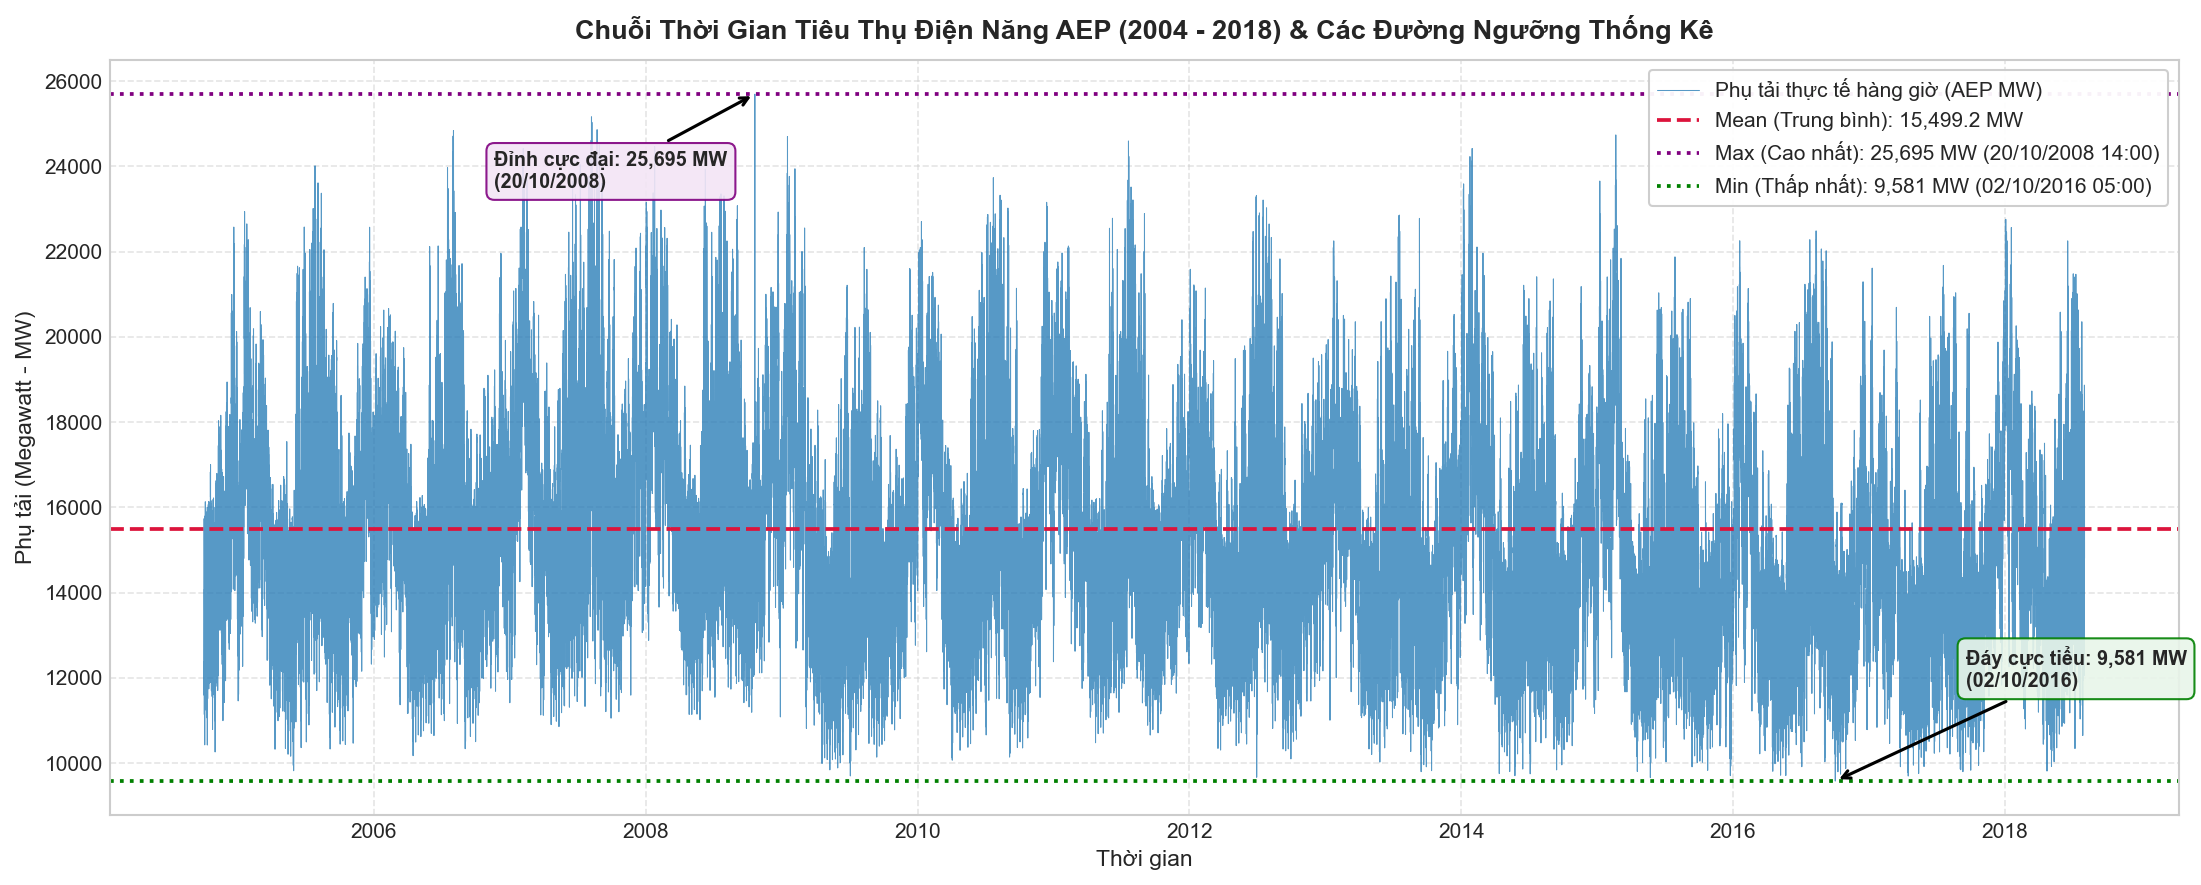

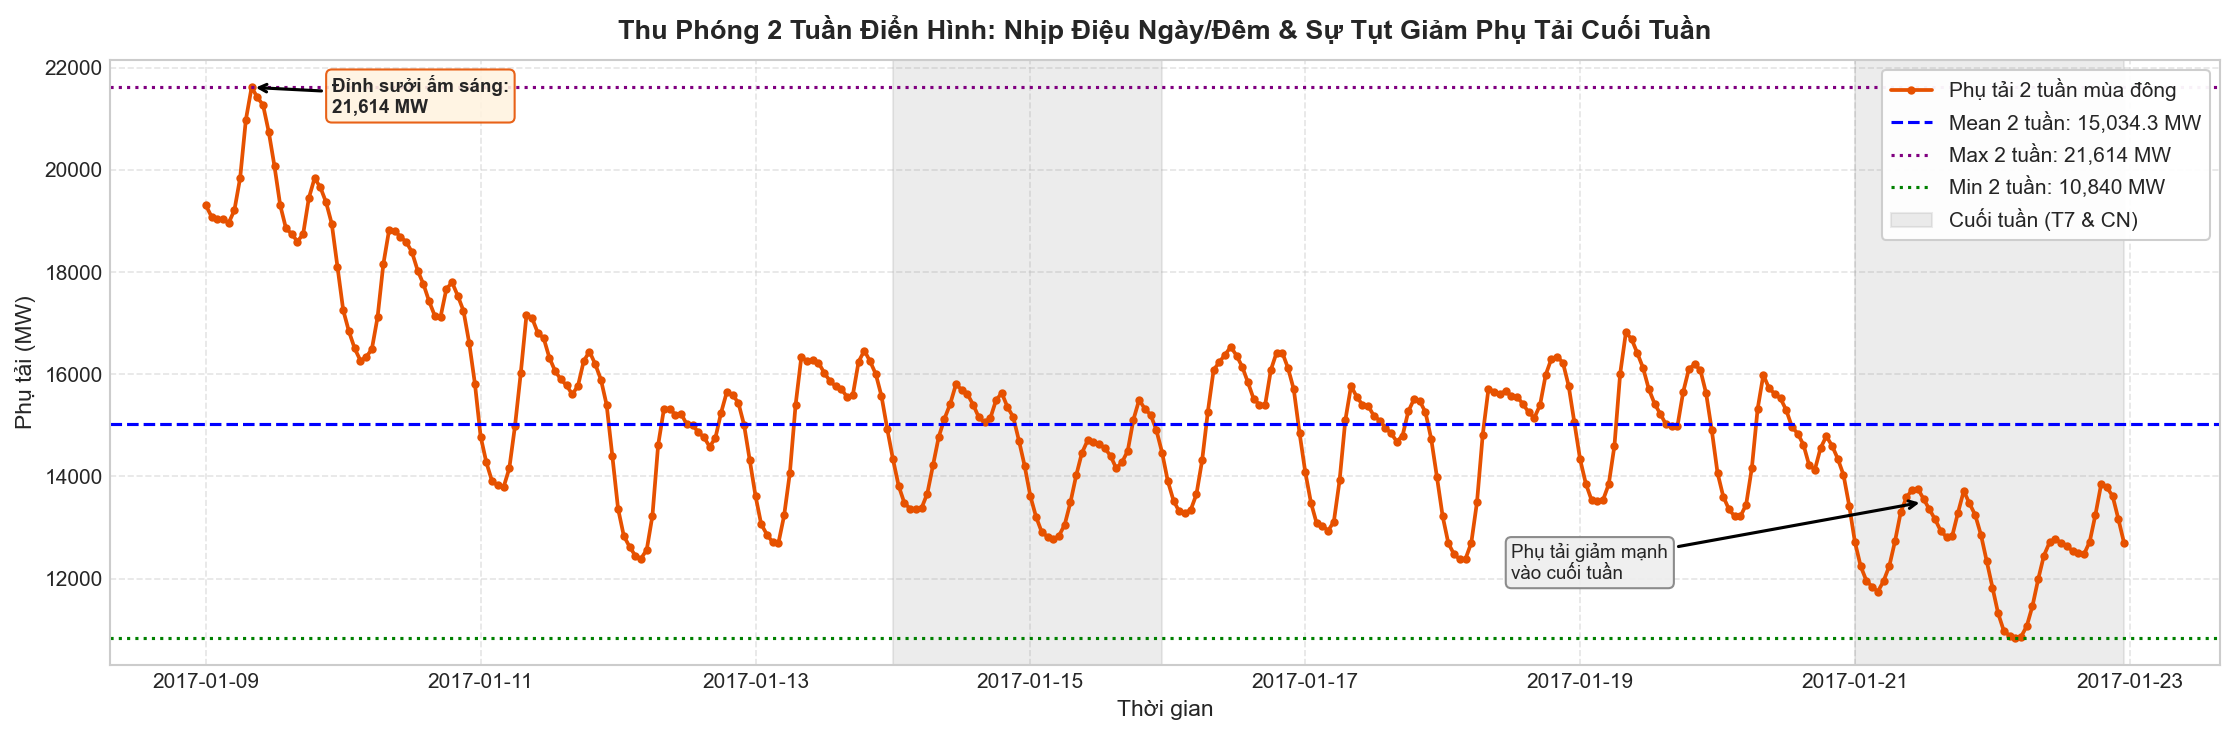

In [8]:
# 5. Vẽ biểu đồ chuỗi thời gian cùng các đường min, max, mean, chú thích và lưu vào docs/images/

mean_val = series.mean()
min_val = series.min()
max_val = series.max()

# --- BIỂU ĐỒ 1: Toàn cảnh 2004 - 2018 với đường Mean, Min, Max và Chú thích ---
plt.figure(figsize=(15, 6), dpi=150)
plt.plot(series.index, series.values, color='#1f77b4', linewidth=0.5, alpha=0.75, label='Phụ tải thực tế hàng giờ (AEP MW)')

# Vẽ các đường ngưỡng min, max, mean
plt.axhline(mean_val, color='crimson', linestyle='--', linewidth=1.8, label=f'Mean (Trung bình): {mean_val:,.1f} MW')
plt.axhline(max_val, color='purple', linestyle=':', linewidth=1.8, label=f'Max (Cao nhất): {max_val:,.0f} MW ({max_date.strftime("%d/%m/%Y %H:00")})')
plt.axhline(min_val, color='green', linestyle=':', linewidth=1.8, label=f'Min (Thấp nhất): {min_val:,.0f} MW ({min_date.strftime("%d/%m/%Y %H:00")})')

# Chú thích điểm cực đại và cực tiểu
plt.annotate(f'Đỉnh cực đại: {max_val:,.0f} MW\n({max_date.strftime("%d/%m/%Y")})', 
             xy=(max_date, max_val), 
             xytext=(max_date - pd.Timedelta(days=700), max_val - 2200),
             arrowprops=dict(facecolor='purple', arrowstyle='->', lw=1.5),
             bbox=dict(boxstyle='round,pad=0.4', facecolor='#F3E5F5', edgecolor='purple', alpha=0.9),
             fontsize=9.5, fontweight='bold')

plt.annotate(f'Đáy cực tiểu: {min_val:,.0f} MW\n({min_date.strftime("%d/%m/%Y")})', 
             xy=(min_date, min_val), 
             xytext=(min_date + pd.Timedelta(days=350), min_val + 2200),
             arrowprops=dict(facecolor='green', arrowstyle='->', lw=1.5),
             bbox=dict(boxstyle='round,pad=0.4', facecolor='#E8F5E9', edgecolor='green', alpha=0.9),
             fontsize=9.5, fontweight='bold')

plt.title('Chuỗi Thời Gian Tiêu Thụ Điện Năng AEP (2004 - 2018) & Các Đường Ngưỡng Thống Kê', fontsize=13, fontweight='bold', pad=10)
plt.xlabel('Thời gian', fontsize=11)
plt.ylabel('Phụ tải (Megawatt - MW)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right', frameon=True, framealpha=0.95, facecolor='white')
plt.tight_layout()
plt.savefig('../docs/images/01_aep_full_timeseries.png', dpi=150, bbox_inches='tight')
plt.show()

# --- BIỂU ĐỒ 2: Thu phóng 2 tuần điển hình với đường Mean 2 tuần và Chú thích chu kỳ ---
sample_2weeks = series.loc['2017-01-09':'2017-01-22']
sample_mean = sample_2weeks.mean()
sample_max = sample_2weeks.max()
sample_min = sample_2weeks.min()
sample_max_date = sample_2weeks.idxmax()

plt.figure(figsize=(15, 5), dpi=150)
plt.plot(sample_2weeks.index, sample_2weeks.values, color='#e65100', linewidth=1.8, marker='o', markersize=3, label='Phụ tải 2 tuần mùa đông')
plt.axhline(sample_mean, color='blue', linestyle='--', linewidth=1.5, label=f'Mean 2 tuần: {sample_mean:,.1f} MW')
plt.axhline(sample_max, color='purple', linestyle=':', linewidth=1.5, label=f'Max 2 tuần: {sample_max:,.0f} MW')
plt.axhline(sample_min, color='green', linestyle=':', linewidth=1.5, label=f'Min 2 tuần: {sample_min:,.0f} MW')

# Vùng tô xám đánh dấu hai kỳ nghỉ cuối tuần (Thứ Bảy & Chủ Nhật)
plt.axvspan(pd.Timestamp('2017-01-14 00:00:00'), pd.Timestamp('2017-01-15 23:00:00'), color='gray', alpha=0.15, label='Cuối tuần (T7 & CN)')
plt.axvspan(pd.Timestamp('2017-01-21 00:00:00'), pd.Timestamp('2017-01-22 23:00:00'), color='gray', alpha=0.15)

# Chú thích đỉnh phụ tải và sự sụt giảm cuối tuần
plt.annotate(f'Đỉnh sưởi ấm sáng:\n{sample_max:,.0f} MW',
             xy=(sample_max_date, sample_max),
             xytext=(sample_max_date + pd.Timedelta(hours=14), sample_max - 500),
             arrowprops=dict(facecolor='#e65100', arrowstyle='->', lw=1.5),
             bbox=dict(boxstyle='round,pad=0.3', facecolor='#FFF3E0', edgecolor='#e65100', alpha=0.9),
             fontsize=9, fontweight='bold')

plt.annotate('Phụ tải giảm mạnh\nvào cuối tuần',
             xy=(pd.Timestamp('2017-01-21 12:00:00'), 13500),
             xytext=(pd.Timestamp('2017-01-18 12:00:00'), 12000),
             arrowprops=dict(facecolor='dimgray', arrowstyle='->', lw=1.5),
             bbox=dict(boxstyle='round,pad=0.3', facecolor='#EEEEEE', edgecolor='gray', alpha=0.9),
             fontsize=9)

plt.title('Thu Phóng 2 Tuần Điển Hình: Nhịp Điệu Ngày/Đêm & Sự Tụt Giảm Phụ Tải Cuối Tuần', fontsize=13, fontweight='bold', pad=10)
plt.xlabel('Thời gian', fontsize=11)
plt.ylabel('Phụ tải (MW)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right', frameon=True, framealpha=0.95, facecolor='white')
plt.tight_layout()
plt.savefig('../docs/images/02_aep_zoomin_2weeks.png', dpi=150, bbox_inches='tight')
plt.show()

**Nhận xét từ thống kê mô tả & biểu đồ:**
1. **Mức trung bình & biến động:** Mức tiêu thụ điện trung bình đạt **~15.500 MW**, dao động trong khoảng $9.581 - 25.695\text{ MW}$ với độ lệch chuẩn $2.591\text{ MW}$.
2. **Đỉnh cực đại (Max):** Đạt kỷ lục $25.695\text{ MW}$ vào ngày **20/10/2008** (và các đợt rét cực đoan mùa đông), đây là những biến cố thời tiết thực tế.
3. **Chu kỳ ngày/đêm & tuần:** Đồ thị thu phóng 2 tuần cho thấy rõ 2 đỉnh phụ tải mỗi ngày (đỉnh sáng và đỉnh tối) cùng vùng phụ tải tụt sâu vào Thứ Bảy, Chủ Nhật. Đây là thông tin cơ sở để quyết định số lượng biến trễ ở **Bước 2** (ví dụ lag 24h và lag 168h).

## Bước 2. Tạo Lag Features (Supervised Learning)

**1. Mục tiêu:** Chuyển đổi bài toán chuỗi thời gian đơn biến $y_t$ thành bài toán học có giám sát (Supervised Learning).

**2. Mô hình hóa toán học:**
Tại mỗi thời điểm tiếp theo $t$, ta dự đoán giá trị $y_t$ dựa trên $p$ giá trị quan sát trong quá khứ:
$$\hat{y}_t = f(y_{t-1}, y_{t-2}, \dots, y_{t-p})$$
Trong đó:
- $y_t$ (**Target**): Giá trị phụ tải điện thực tế cần dự đoán tại thời điểm $t$.
- $y_{t-1}, y_{t-2}, \dots, y_{t-p}$ (**Features / Lag Predictors**): Các biến trễ tương ứng với phụ tải tại các thời điểm $t-1, t-2, \dots, t-p$.

**3. Thiết lập bậc trễ $p = 24$:**
Dữ liệu phụ tải điện AEP có tính chu kỳ ngày rất mạnh (24 giờ). Việc chọn $p = 24$ bước trễ liên tục giúp mô hình nắm bắt trọn vẹn diễn biến phụ tải trong 24 giờ của ngày hôm trước.

**4. Cơ chế trượt thời gian & xử lý giá trị khuyết (NaN):**
- Sử dụng hàm `shift(i)` của Pandas để dịch chuyển chuỗi dữ liệu lùi lại $i$ bước thời gian.
- Quá trình này tạo ra đúng $p$ dòng `NaN` ở đầu chuỗi (do $p$ giờ đầu tiên không có đủ lịch sử quá khứ).
- Thực hiện `.dropna()` để loại bỏ $p$ dòng này, đảm bảo ma trận $X$ hoàn chỉnh và sạch 100% trước khi huấn luyện.

In [9]:
# ==============================================================================
# BƯỚC 2: TẠO LAG FEATURES (SUPERVISED LEARNING)
# ==============================================================================

def create_lag_features(data_series, p=24):
    """
    Chuyển đổi chuỗi thời gian đơn biến thành bài toán học có giám sát với p bậc trễ.
    
    Parameters:
    -----------
    data_series : pd.Series
        Chuỗi thời gian liên tục với DatetimeIndex.
    p : int, default=24
        Số bậc trễ (lag order) cần tạo.
        
    Returns:
    --------
    df_features : pd.DataFrame
        DataFrame chứa cột target 'y' và các cột đặc trưng 'lag_1' đến 'lag_p',
        đã loại bỏ các dòng NaN do trượt dữ liệu.
    """
    df_feat = pd.DataFrame({'y': data_series})
    for i in range(1, p + 1):
        df_feat[f'lag_{i}'] = data_series.shift(i)
        
    # Loại bỏ p dòng đầu tiên chứa NaN
    df_clean = df_feat.dropna()
    return df_clean

# 1. Khởi tạo số bậc trễ p = 24 (tương ứng chu kỳ 24 giờ của 1 ngày)
p_lags = 24
df_supervised = create_lag_features(series, p=p_lags)

# 2. Kiểm tra thông tin tập dữ liệu sau khi biến đổi
print(f"=== KẾT QUẢ TẠO LAG FEATURES (p = {p_lags}) ===")
print(f"- Kích thước ma trận (dòng, cột): {df_supervised.shape}")
print(f"- Số dòng ban đầu:               {len(series):,} dòng")
print(f"- Số dòng sau khi dropna:        {len(df_supervised):,} dòng (mất {len(series) - len(df_supervised)} dòng đầu do shift)")
print(f"- Số giá trị thiếu (NaN):        {df_supervised.isnull().sum().sum()}")
print(f"- Dải thời gian khả dụng:        {df_supervised.index.min()}  -->  {df_supervised.index.max()}")

print("\n--- 5 DÒNG ĐẦU TIÊN CỦA MA TRẬN HỌC CÓ GIÁM SÁT ---")
print(df_supervised[['y', 'lag_1', 'lag_2', 'lag_3', 'lag_23', 'lag_24']].head())

print("\n--- 5 DÒNG CUỐI CÙNG CỦA MA TRẬN HỌC CÓ GIÁM SÁT ---")
print(df_supervised[['y', 'lag_1', 'lag_2', 'lag_3', 'lag_23', 'lag_24']].tail())


=== KẾT QUẢ TẠO LAG FEATURES (p = 24) ===
- Kích thước ma trận (dòng, cột): (121272, 25)
- Số dòng ban đầu:               121,296 dòng
- Số dòng sau khi dropna:        121,272 dòng (mất 24 dòng đầu do shift)
- Số giá trị thiếu (NaN):        0
- Dải thời gian khả dụng:        2004-10-02 01:00:00  -->  2018-08-03 00:00:00

--- 5 DÒNG ĐẦU TIÊN CỦA MA TRẬN HỌC CÓ GIÁM SÁT ---
                           y    lag_1    lag_2    lag_3   lag_23   lag_24
Datetime                                                                 
2004-10-02 01:00:00  12260.0  13147.0  14067.0  14837.0  11935.0  12379.0
2004-10-02 02:00:00  11672.0  12260.0  13147.0  14067.0  11692.0  11935.0
2004-10-02 03:00:00  11352.0  11672.0  12260.0  13147.0  11597.0  11692.0
2004-10-02 04:00:00  11177.0  11352.0  11672.0  12260.0  11681.0  11597.0
2004-10-02 05:00:00  11142.0  11177.0  11352.0  11672.0  12280.0  11681.0

--- 5 DÒNG CUỐI CÙNG CỦA MA TRẬN HỌC CÓ GIÁM SÁT ---
                           y    lag_1    lag_2    lag

**Đánh giá & Kết luận Bước 2:**
1. **Chuyển đổi thành công:** Đã cấu trúc hóa chuỗi đơn biến $121.296$ giờ thành bảng dữ liệu học có giám sát gồm **$121.272$ mẫu** và **$25$ cột** ($1$ cột target $y$ và $24$ đặc trưng trễ $lag_1 \dots lag_{24}$).
2. **Bảo toàn nguyên tắc nhân quả (No Data Leakage):** Mọi đặc trưng tại thời điểm $t$ đều được lấy nghiêm ngặt từ quá khứ ($t-1, \dots, t-24$). Không có thông tin tương lai bị rò rỉ vào ma trận đặc trưng.
3. **Tổn thất mẫu tối thiểu:** Chỉ mất đúng $24$ dòng đầu tiên (~$0.019\%$ dữ liệu) do quá trình `shift()`, dải thời gian liên tục từ `2004-10-02 01:00:00` đến `2018-08-03 00:00:00` được bảo toàn nguyên vẹn.
4. **Sẵn sàng cho Bước 3:** Dữ liệu đã đạt chuẩn để tách $X - y$ và phân chia tập huấn luyện / kiểm thử theo thời gian.